# Part 4 — Frozen pretrained features and CLIP

This notebook uses one shared pipeline for ResNet-18, ViT-B/32, and DINOv2: extract and cache image features, train a linear SVM, and evaluate on the supplied validation split. ResNet uses global average pooled outputs from its final three residual blocks; ViT and DINOv2 use their global image embeddings.

CLIP zero-shot is evaluated separately because it ranks image–text similarities and does not train an SVM. The supplied data has train/validation splits only, so validation results are the final reported evaluation for this notebook.

In [1]:
from pathlib import Path
from time import perf_counter

import clip
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
)
from sklearn.preprocessing import normalize
from sklearn.svm import LinearSVC

from src.deep_models import IntermediateFeatureExtractor, getModel
from src.utils import loadSamplesTable

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

DATA_DIR = Path("data")
CACHE_DIR = DATA_DIR / "deep_features"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

train_df = loadSamplesTable("data/splits", "data/images", subset="train")
val_df = loadSamplesTable("data/splits", "data/images", subset="val")
target_categories = ["aeroplane", "motorbike", "person", "horse", "car"]
all_categories = sorted(train_df["category"].unique())

print("Train images:", len(train_df), "Validation images:", len(val_df))
print("Categories:", all_categories)
assert set(train_df["category"]) == set(val_df["category"])

Device: cpu
Train images: 2791 Validation images: 2796
Categories: ['aeroplane', 'background', 'car', 'horse', 'motorbike', 'person']


## Shared feature extraction function

The data loop and caching are shared. Only the model forward pass changes: ResNet collects and pools three intermediate feature maps, ViT/DINOv2 return their global embedding, and CLIP uses `encode_image`.

In [2]:
RESNET_LAYERS = ("layer2.1", "layer3.1", "layer4.1")

def extract_image_vectors(
    df, model, preprocess, *, mode, device, batch_size=16, extractor=None
):
    """Extract one feature vector per image, in dataframe row order."""
    output_batches = []

    for start in range(0, len(df), batch_size):
        rows = list(df.iloc[start:start + batch_size].itertuples())
        images = []
        for row in rows:
            with Image.open(row.filepath) as image:
                images.append(preprocess(image.convert("RGB")))

        batch = torch.stack(images).to(device)
        with torch.inference_mode():
            if mode == "resnet_last3":
                _, layer_outputs = extractor(batch)
                vectors = [
                    layer_outputs[name].mean(dim=(2, 3))
                    for name in RESNET_LAYERS
                ]
                features = torch.cat(vectors, dim=1)
            elif mode == "clip_image":
                features = model.encode_image(batch)
            else:
                features = model(batch)

            # Keep this robust to model APIs that return a tuple.
            if isinstance(features, (tuple, list)):
                features = features[0]

        output_batches.append(features.float().cpu().numpy())

    return np.concatenate(output_batches, axis=0)


def get_or_extract_features(model_name, batch_size=16, force=False):
    """Load cached train/val features, or extract and cache them."""
    cache_path = CACHE_DIR / f"{model_name}_features.npz"
    if cache_path.exists() and not force:
        with np.load(cache_path, allow_pickle=True) as saved:
            # Check cached rows still match the current split ordering.
            if (
                np.array_equal(saved["train_names"], train_df["filename"].to_numpy())
                and np.array_equal(saved["val_names"], val_df["filename"].to_numpy())
            ):
                print(f"Using cached features: {cache_path}")
                return {
                    key: saved[key]
                    for key in (
                        "x_train", "x_val", "y_train", "y_val",
                        "train_names", "val_names",
                        "train_extract_seconds", "val_extract_seconds",
                    )
                }

    model, preprocess = getModel(model_name, device=device, nofc=True, prefer_local=(model_name == "dinov2_vits14"))
    mode = "resnet_last3" if model_name == "resnet18" else "global"
    extractor = IntermediateFeatureExtractor(model) if mode == "resnet_last3" else None

    try:
        start = perf_counter()
        x_train = extract_image_vectors(
            train_df, model, preprocess, mode=mode, device=device,
            batch_size=batch_size, extractor=extractor,
        )
        train_extract_seconds = perf_counter() - start

        start = perf_counter()
        x_val = extract_image_vectors(
            val_df, model, preprocess, mode=mode, device=device,
            batch_size=batch_size, extractor=extractor,
        )
        val_extract_seconds = perf_counter() - start
    finally:
        if extractor is not None:
            extractor.remove_hooks()

    result = {
        "x_train": x_train,
        "x_val": x_val,
        "y_train": train_df["category"].to_numpy(),
        "y_val": val_df["category"].to_numpy(),
        "train_names": train_df["filename"].to_numpy(),
        "val_names": val_df["filename"].to_numpy(),
        "train_extract_seconds": np.array(train_extract_seconds),
        "val_extract_seconds": np.array(val_extract_seconds),
    }
    np.savez_compressed(cache_path, **result)
    print(f"Saved features: {cache_path}")
    return result

## SVM evaluation for ResNet-18, ViT-B/32, and DINOv2

All three use the same L2 normalization and linear SVM. The fixed `C=1` avoids tuning on the evaluation split. Feature extraction time includes image loading, preprocessing, and model inference; SVM scoring time is measured separately.

In [3]:
def evaluate_linear_svm(model_name, feature_data, C=1.0):
    x_train = normalize(feature_data["x_train"], norm="l2")
    x_val = normalize(feature_data["x_val"], norm="l2")
    y_train = feature_data["y_train"]
    y_val = feature_data["y_val"]

    classifier = LinearSVC(C=C, max_iter=20_000, random_state=42)
    start = perf_counter()
    classifier.fit(x_train, y_train)
    fit_seconds = perf_counter() - start

    start = perf_counter()
    val_scores = classifier.decision_function(x_val)
    scoring_seconds = perf_counter() - start
    val_predictions = classifier.predict(x_val)

    class_names = list(classifier.classes_)
    ap_by_class = {}
    for category in target_categories:
        col = class_names.index(category)
        ap_by_class[category] = average_precision_score(
            y_val == category, val_scores[:, col]
        )

    row = {
        "method": model_name,
        "mAP": float(np.mean(list(ap_by_class.values()))),
        "feature_dim": int(x_train.shape[1]),
        "train_extract_s": float(feature_data["train_extract_seconds"]),
        "val_extract_s": float(feature_data["val_extract_seconds"]),
        "svm_fit_s": fit_seconds,
        "score_ms_per_image": 1000 * scoring_seconds / len(y_val),
        "macro_F1": f1_score(y_val, val_predictions, average="macro"),
        "cache_size_MiB": (
            CACHE_DIR / f"{model_name}_features.npz"
        ).stat().st_size / (1024 ** 2),
    }

    print(f"\n{model_name}: per-class AP")
    display(pd.Series(ap_by_class, name="AP"))
    print("Confusion matrix class order:", class_names)
    display(pd.DataFrame(
        confusion_matrix(y_val, val_predictions, labels=class_names),
        index=class_names,
        columns=class_names,
    ))
    return row, ap_by_class


MODEL_NAMES = ("resnet18", "vit_b_32", "dinov2_vits14")
deep_rows = []
deep_ap = {}

for model_name in MODEL_NAMES:
    features = get_or_extract_features(model_name)
    row, ap_by_class = evaluate_linear_svm(model_name, features, C=1.0)
    deep_rows.append(row)
    deep_ap[model_name] = ap_by_class
    del features
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

deep_results = pd.DataFrame(deep_rows)
display(deep_results.round(4))

Using cached features: data/deep_features/resnet18_features.npz

resnet18: per-class AP


aeroplane    0.940101
motorbike    0.543764
person       0.847531
horse        0.509496
car          0.743975
Name: AP, dtype: float64

Confusion matrix class order: ['aeroplane', 'background', 'car', 'horse', 'motorbike', 'person']


,aeroplane,background,car,horse,motorbike,person
aeroplane,108,10,1,0,0,7
background,1,1029,16,4,0,27
car,4,40,245,1,7,40
horse,0,18,0,61,0,69
motorbike,1,8,11,0,52,53
person,8,110,81,45,29,710


Using cached features: data/deep_features/vit_b_32_features.npz

vit_b_32: per-class AP


aeroplane    0.926791
motorbike    0.571730
person       0.824135
horse        0.543221
car          0.744449
Name: AP, dtype: float64

... (3 outputs left out)

aeroplane    0.903766
motorbike    0.637548
person       0.870254
horse        0.622019
car          0.744077
Name: AP, dtype: float64

Confusion matrix class order: ['aeroplane', 'background', 'car', 'horse', 'motorbike', 'person']


,aeroplane,background,car,horse,motorbike,person
aeroplane,126,0,0,0,0,0
background,3,1040,14,0,0,20
car,2,25,266,3,6,35
horse,0,7,0,88,0,53
motorbike,0,4,4,0,74,43
person,13,81,77,61,40,711


,method,mAP,feature_dim,train_extract_s,val_extract_s,svm_fit_s,score_ms_per_image,macro_F1,cache_size_MiB
0,resnet18,0.7170,896,122.3730,167.3914,1.3237,0.0104,0.6982,17.3659
1,vit_b_32,0.7221,768,300.8654,280.1285,1.2028,0.0014,0.7243,15.2122
2,dinov2_vits14,0.7555,384,429.8190,427.2892,0.5776,0.0019,0.7647,7.6127


## CLIP zero-shot classification

CLIP uses one text embedding per class and ranks images by cosine similarity. This cell compares a few prompt templates; because there is no separate test split, treat this as prompt-sensitivity analysis rather than an unbiased prompt-selection test.

In [4]:
# Cache CLIP validation image embeddings separately from the SVM features.
clip_cache = CACHE_DIR / "clip_vit_b_32_val_images.npz"
clip_image_features = None

if clip_cache.exists():
    try:
        with np.load(clip_cache, allow_pickle=False) as saved:
            cached_names = saved["val_names"].astype(str)
            current_names = val_df["filename"].astype(str).to_numpy()

            if np.array_equal(cached_names, current_names):
                clip_image_features = saved["image_features"]
                clip_extract_seconds = float(saved["extract_seconds"])
    except ValueError as exc:
        if "object arrays cannot be loaded" not in str(exc).lower():
            raise
        print("Old CLIP cache has object dtype filenames; regenerating it")

clip_model, clip_preprocess = getModel(
    "clip_vit_b_32", device=device, nofc=True
)

if clip_image_features is None:
    start = perf_counter()
    clip_image_features = extract_image_vectors(
        val_df, clip_model, clip_preprocess, mode="clip_image",
        device=device, batch_size=16,
    )
    clip_extract_seconds = perf_counter() - start
    np.savez_compressed(
        clip_cache,
        image_features=clip_image_features,
        val_names=val_df["filename"].astype(str).to_numpy(),
        extract_seconds=np.array(clip_extract_seconds),
    )

clip_image_features = normalize(clip_image_features, norm="l2")

clip_class_words = {
    "aeroplane": "airplane",
    "motorbike": "motorbike",
    "person": "person",
    "horse": "horse",
    "car": "car",
    "background": "background scene",
}
prompt_templates = (
    "a photo of a {}",
    "a picture of a {}",
    "an image showing a {}",
)

def clip_scores_for_template(template):
    start = perf_counter()
    prompts = [template.format(clip_class_words[c]) for c in all_categories]
    tokens = clip.tokenize(prompts).to(device)
    with torch.inference_mode():
        text_features = clip_model.encode_text(tokens).float()
        text_features = text_features / text_features.norm(dim=1, keepdim=True)
    # Cosine similarities; multiplying all scores by one constant is unnecessary.
    scores = clip_image_features @ text_features.cpu().numpy().T
    return scores, perf_counter() - start

clip_prompt_rows = []
clip_prompt_scores = {}
for template in prompt_templates:
    scores, score_seconds = clip_scores_for_template(template)
    clip_prompt_scores[template] = scores
    ap_by_class = {
        category: average_precision_score(
            val_df["category"].to_numpy() == category,
            scores[:, all_categories.index(category)],
        )
        for category in target_categories
    }
    predictions = np.asarray(all_categories)[np.argmax(scores, axis=1)]
    clip_prompt_rows.append({
        "prompt_template": template,
        "mAP": float(np.mean(list(ap_by_class.values()))),
        "macro_F1": f1_score(
            val_df["category"], predictions, labels=all_categories,
            average="macro",
        ),
        "per_class_AP": ap_by_class,
        "score_ms_per_image": 1000 * score_seconds / len(val_df),
    })

clip_prompt_results = pd.DataFrame(clip_prompt_rows)
display(clip_prompt_results[["prompt_template", "mAP", "macro_F1"]].round(4))
display(pd.DataFrame(
    [row["per_class_AP"] for row in clip_prompt_rows],
    index=[row["prompt_template"] for row in clip_prompt_rows],
).round(4))

# Report the first prompt as the predefined CLIP baseline in the model table.
baseline_clip = clip_prompt_rows[0]
clip_results_row = {
    "method": "clip_zero_shot",
    "mAP": baseline_clip["mAP"],
    "feature_dim": int(clip_image_features.shape[1]),
    "train_extract_s": np.nan,
    "val_extract_s": clip_extract_seconds,
    "svm_fit_s": np.nan,
    "score_ms_per_image": baseline_clip["score_ms_per_image"],
    "macro_F1": baseline_clip["macro_F1"],
    "cache_size_MiB": clip_cache.stat().st_size / (1024 ** 2),
}

comparison_table = pd.concat(
    [deep_results, pd.DataFrame([clip_results_row])],
    ignore_index=True,
)
display(comparison_table.round(4))
print("CLIP confusion matrix for the predefined prompt:")
clip_baseline_scores = clip_prompt_scores[prompt_templates[0]]
clip_predictions = np.asarray(all_categories)[np.argmax(clip_baseline_scores, axis=1)]
display(pd.DataFrame(
    confusion_matrix(
        val_df["category"], clip_predictions, labels=all_categories
    ),
    index=all_categories,
    columns=all_categories,
))

Old CLIP cache has object dtype filenames; regenerating it


/home/luis/Desktop/iacv_labs/.venv/lib/python3.11/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


,prompt_template,mAP,macro_F1
0,a photo of a {},0.6427,0.6229
1,a picture of a {},0.6433,0.6107
2,an image showing a {},0.6278,0.5913


,aeroplane,motorbike,person,horse,car
a photo of a {},0.9030,0.5420,0.5265,0.5677,0.6742
a picture of a {},0.9013,0.5625,0.4904,0.5764,0.6857
an image showing a {},0.9087,0.5061,0.5754,0.5407,0.6080


,method,mAP,feature_dim,train_extract_s,val_extract_s,svm_fit_s,score_ms_per_image,macro_F1,cache_size_MiB
0,resnet18,0.7170,896,122.3730,167.3914,1.3237,0.0104,0.6982,17.3659
1,vit_b_32,0.7221,768,300.8654,280.1285,1.2028,0.0014,0.7243,15.2122
2,dinov2_vits14,0.7555,384,429.8190,427.2892,0.5776,0.0019,0.7647,7.6127
3,clip_zero_shot,0.6427,512,NaN,253.6254,NaN,0.1598,0.6229,5.0728


CLIP confusion matrix for the predefined prompt:


,aeroplane,background,car,horse,motorbike,person
aeroplane,125,1,0,0,0,0
background,9,600,32,137,33,266
car,2,77,225,7,21,5
horse,0,3,1,144,0,0
motorbike,0,2,0,1,120,2
person,14,250,67,136,120,396


# Part 4 — Questions and answers

### Q1. How do learned features differ from handcrafted local descriptors? Does a higher-dimensional feature necessarily give better AP?

**A:** Handcrafted BoVW/VLAD/FV features summarize local SIFT descriptors using a fixed vocabulary or mixture model. Pretrained CNN/ViT features are learned representations; the SVM learns a linear decision rule on top of features learned during large-scale pretraining.

**Evidence:** Part 1 BoVW had five-category mAP **0.6037**. Here, ResNet-18, ViT-B/32, and DINOv2 reached **0.7170**, **0.7221**, and **0.7555**. DINOv2 has the smallest feature (384 dimensions), while ResNet has 896 and ViT 768, so higher dimension did not mean higher AP. This is descriptive, not fully controlled: Part 1 used SVM C=10 and Part 4 used C=1.

### Q2. Why can DINOv2 features be useful with few labeled examples even though DINOv2 is not trained as a classifier for these target categories?

**A:** Self-supervised pretraining can produce reusable representations of shapes, textures, and object structure. A linear classifier can use those features to separate target classes without learning visual features from scratch.

**Evidence:** The few-shot motorbike experiment reached mean validation AP **0.499** with 5 positive examples and **0.549** with 10; using all 120 positives reached **0.551** in this balanced binary setup. This suggests the pretrained features reduce label needs, though the one-example result (**0.221 ± 0.212**) is unstable. This experiment compares sample counts within DINOv2, not against training a backbone from scratch.

### Q3. What information might be lost when patch tokens are replaced by a single global descriptor?

**A:** Pooling patch tokens into one vector discards their explicit locations and much of the spatial arrangement between object parts. It may weaken distinctions involving small objects, multiple objects, or object-versus-background layout.

**Evidence:** The same-split DINOv2 comparison gave mAP **0.7555** for the CLS token and **0.7564** for the mean of patch tokens—nearly identical overall. The patch mean improved aeroplane AP (**0.9038 → 0.9483**) and person (**0.8703 → 0.8805**), but lowered motorbike (**0.6375 → 0.6104**) and horse (**0.6220 → 0.5888**). This test averages patch tokens too, so it does not test retaining spatial locations individually.

### Q4. How much does pretrained representation quality reduce dependence on labeled examples?

**A:** In this motorbike experiment, DINOv2 reaches almost its full-data AP with around 10 positive examples, though results vary across seeds and do not improve monotonically.

**Evidence:** Mean AP was **0.221 ± 0.212** with 1 positive, **0.499 ± 0.059** with 5, **0.549 ± 0.037** with 10, **0.526 ± 0.023** with 20, and **0.551 ± 0.008** with all 120. Negatives were sampled in equal number from all non-motorbike training images. This is evidence of data efficiency for this pretrained representation and setup; it is not a comparison to a model trained from scratch.

### Q5. When could horizontal flipping harm recognition? Is averaging feature vectors equivalent to averaging classifier scores?

**A:** Flipping can hurt when left/right orientation, text, or asymmetric context matters, or when it creates an implausible example. For a linear classifier (f(x)=w^Tx+b), scoring the unnormalized mean feature equals averaging the scores: (f((x_1+x_2)/2)=(f(x_1)+f(x_2))/2). Normalizing the mean afterward generally breaks that equality.

**Evidence:** Adding flipped training examples made almost no difference with 5 positives (**0.4991 vs 0.4989**) and slightly reduced mean AP with 10 (**0.5415 vs 0.5492**), 20 (**0.5201 vs 0.5255**), and 120 (**0.5446 vs 0.5511**). At 1 positive it was slightly higher (**0.2337 vs 0.2211**), but both standard deviations were large. This run provides no evidence that flipping helps overall.

### Q6. How does regularization affect the bias–variance trade-off when only a few positive examples are available?

**A:** Smaller C means stronger regularization and can improve generalization when the training set is tiny; larger C penalizes training errors more and can increase overfitting. Excessively small C can also underfit.

**Evidence:** With five motorbike positives, training AP was **1.0 for every C** tested, while validation AP fell from **0.5610** at C=0.1 to **0.5487**, **0.5359**, **0.5327**, and **0.5323** at C=1, 10, 100, and 1000. The tiny training set is perfectly separable for all settings, but the increasing gap as C grows is consistent with overfitting. Because validation is also the final available evaluation split, this sweep is exploratory/model selection rather than an independent test estimate.

### Q7. How does CLIP zero-shot recognition differ from a linear SVM trained on frozen CLIP image embeddings?

**A:** CLIP zero-shot compares image embeddings directly with text embeddings for candidate class descriptions and needs no target-specific labeled training examples. An SVM on frozen CLIP image embeddings would instead learn a decision boundary from this dataset’s labels.

**Evidence:** The predefined CLIP prompt achieved mAP **0.6427** and macro-F1 **0.6229**. DINOv2 + SVM achieved mAP **0.7555** and macro-F1 **0.7647**. This is not a controlled supervision comparison: DINO’s SVM uses task labels; CLIP zero-shot does not.

### Q8. How sensitive are predictions to prompt wording? What are the risks of selecting prompts based on the test set?

**A:** Overall mAP changed modestly across these three templates, but class AP changed more. Selecting wording based on evaluation labels leaks information and makes the reported score optimistic.

**Evidence:** CLIP mAP was **0.6427** for “a photo of a {}”, **0.6433** for “a picture of a {}”, and **0.6278** for “an image showing a {}”. Person AP ranged from **0.4904 to 0.5754**; aeroplane stayed near **0.90**. The first template remains the predefined baseline; the best-scoring template should not be described as an independent test result.

### Q9. Do the highlighted regions correspond to the object? What can and cannot be concluded from a saliency visualization?

**A:** In the inspected ResNet SVM-CAM examples, the strongest positive region overlapped the motorbike, including in one correctly classified image and one image misclassified as background. The heatmap is coarse and can cover nearby context too.

**Evidence and limitation:** The maps were computed from the final ResNet feature map and the motorbike SVM weights. They show locations contributing positively to that linear class score; they do not prove the model causally relies on the object or explain all evidence used by the network.

### Q10. Which categories and visual conditions remain difficult, and what evidence supports your explanation?

**A:** Horse and motorbike remained the hardest categories by DINOv2 AP; aeroplane was easiest. The inspected errors suggest that people/riders and cluttered scenes make horse and motorbike examples ambiguous. Some images labeled person contain a prominent horse or motorcycle, indicating class overlap in the image and possibly ambiguous image-level labels.

**Evidence:** DINOv2 AP was **0.6220** for horse, **0.6375** for motorbike, and **0.9038** for aeroplane. It classified 88/148 horses and 74/121 motorbikes correctly. The error grid showed horses with riders or handlers predicted as person, motorcycles amid cars or people predicted as car/person, and person-labeled images with prominent bikes or horses ranked highly for those object classes. These visual examples support the ambiguity explanation, but do not establish a single cause for every error.

## Experiment for Q3: DINOv2 CLS token versus mean patch token

This compares the global CLS representation already used above with a mean of DINOv2 patch tokens. Both have the same dimension and use the same SVM/split. Run this cell to add measured AP values to the discussion.

In [5]:
def extract_dino_cls_and_patch_mean(df, model, preprocess, batch_size=16):
    cls_batches, patch_batches = [], []

    for start in range(0, len(df), batch_size):
        rows = list(df.iloc[start:start + batch_size].itertuples())
        images = []
        for row in rows:
            with Image.open(row.filepath) as image:
                images.append(preprocess(image.convert("RGB")))
        batch = torch.stack(images).to(device)

        with torch.inference_mode():
            token_output = model.forward_features(batch)
        cls_batches.append(token_output["x_norm_clstoken"].float().cpu().numpy())
        patch_batches.append(
            token_output["x_norm_patchtokens"].mean(dim=1).float().cpu().numpy()
        )

    return np.concatenate(cls_batches), np.concatenate(patch_batches)


# Uses cached CLS embeddings above; extract patch-mean vectors for both splits.
dino_cached = get_or_extract_features("dinov2_vits14")
dino_model, dino_preprocess = getModel("dinov2_vits14", device=device, prefer_local=True)
start = perf_counter()
dino_train_cls_check, dino_train_patch = extract_dino_cls_and_patch_mean(
    train_df, dino_model, dino_preprocess
)
dino_val_cls_check, dino_val_patch = extract_dino_cls_and_patch_mean(
    val_df, dino_model, dino_preprocess
)
del dino_model
patch_extract_seconds = perf_counter() - start

# Confirm this model's forward() output is the same global CLS embedding.
print("Max cached-vs-forward CLS difference:",
      np.max(np.abs(dino_cached["x_val"] - dino_val_cls_check)))

def evaluate_multiclass_map(x_train, y_train, x_val, y_val):
    x_train = normalize(x_train, norm="l2")
    x_val = normalize(x_val, norm="l2")
    clf = LinearSVC(C=1.0, max_iter=20_000, random_state=42)
    clf.fit(x_train, y_train)
    scores = clf.decision_function(x_val)
    class_names = list(clf.classes_)
    aps = {
        category: average_precision_score(
            y_val == category, scores[:, class_names.index(category)]
        )
        for category in target_categories
    }
    return aps

cls_aps = evaluate_multiclass_map(
    dino_cached["x_train"], dino_cached["y_train"],
    dino_cached["x_val"], dino_cached["y_val"],
)
patch_aps = evaluate_multiclass_map(
    dino_train_patch, train_df["category"].to_numpy(),
    dino_val_patch, val_df["category"].to_numpy(),
)
display(pd.DataFrame(
    {"CLS token": cls_aps, "Mean patch tokens": patch_aps}
).assign(
    cls_mAP=np.mean(list(cls_aps.values())),
    patch_mean_mAP=np.mean(list(patch_aps.values())),
).round(4))
print("Patch token extraction time (train + validation, s):",
      round(patch_extract_seconds, 2))

Using cached features: data/deep_features/dinov2_vits14_features.npz
Max cached-vs-forward CLS difference: 0.0


,CLS token,Mean patch tokens,cls_mAP,patch_mean_mAP
aeroplane,0.9038,0.9483,0.7555,0.7564
motorbike,0.6375,0.6104,0.7555,0.7564
person,0.8703,0.8805,0.7555,0.7564
horse,0.6220,0.5888,0.7555,0.7564
car,0.7441,0.7539,0.7555,0.7564


Patch token extraction time (train + validation, s): 775.43


## Experiments for Q4–Q6: few-shot learning, flips, and SVM regularization

DINOv2 is selected because it had the best full-data mAP in the current run. For each repeat, the code samples the specified number of motorbike positives and an equal number of negatives drawn from every other training category. The flip condition adds mirrored versions of those sampled training images. Validation AP is measured for the learning curve; the C sweep is exploratory because this same split is used for final evaluation.

Using cached features: data/deep_features/dinov2_vits14_features.npz


,n_positive,augmentation,mean_AP,std_AP
0,1,horizontal_flip,0.2337,0.2014
1,1,none,0.2211,0.2120
2,5,horizontal_flip,0.4991,0.0593
3,5,none,0.4989,0.0579
4,10,horizontal_flip,0.5415,0.0340
5,10,none,0.5492,0.0374
6,20,horizontal_flip,0.5201,0.0250
7,20,none,0.5255,0.0233
8,120,horizontal_flip,0.5446,0.0148
9,120,none,0.5511,0.0082


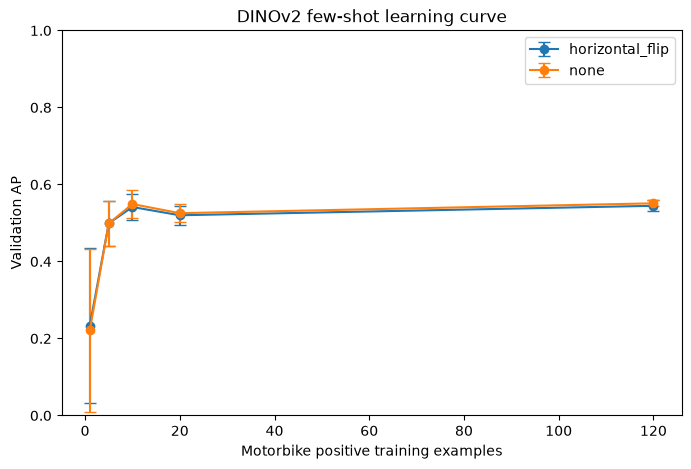

,C,train_AP,val_AP
0,0.1,1.0,0.5610
1,1.0,1.0,0.5487
2,10.0,1.0,0.5359
3,100.0,1.0,0.5327
4,1000.0,1.0,0.5323


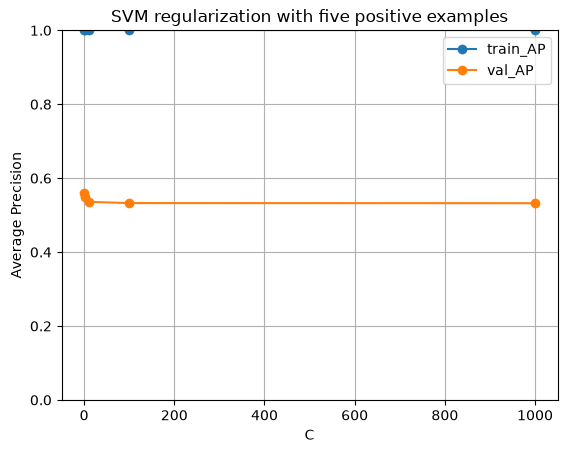

In [6]:
from PIL import ImageOps

# Load DINOv2's cached original image embeddings.
dino_data = get_or_extract_features("dinov2_vits14")
x_train_dino = normalize(dino_data["x_train"], norm="l2")
x_val_dino = normalize(dino_data["x_val"], norm="l2")
y_train_all = train_df["category"].to_numpy()
y_val_binary = (val_df["category"].to_numpy() == "motorbike").astype(int)

positive_indices = np.flatnonzero(y_train_all == "motorbike")
negative_indices = np.flatnonzero(y_train_all != "motorbike")
shot_counts = sorted(set([1, 5, 10, 20, len(positive_indices)]))
seeds = (42, 43, 44)

# Cache mirrored DINO features only for sampled images, not the whole dataset.
flip_feature_cache = {}
flip_model, flip_preprocess = getModel("dinov2_vits14", device=device, prefer_local=True)

def get_mirrored_features(indices, batch_size=16):
    missing = [
        int(i) for i in indices
        if str(train_df.iloc[int(i)]["filename"]) not in flip_feature_cache
    ]
    for start in range(0, len(missing), batch_size):
        batch_indices = missing[start:start + batch_size]
        images = []
        for i in batch_indices:
            with Image.open(train_df.iloc[i]["filepath"]) as image:
                images.append(flip_preprocess(ImageOps.mirror(image.convert("RGB"))))
        batch = torch.stack(images).to(device)
        with torch.inference_mode():
            vectors = flip_model(batch).float().cpu().numpy()
        for i, vector in zip(batch_indices, vectors):
            flip_feature_cache[str(train_df.iloc[i]["filename"])] = vector

    return np.stack([
        flip_feature_cache[str(train_df.iloc[int(i)]["filename"])]
        for i in indices
    ])

fewshot_rows = []
for seed in seeds:
    rng = np.random.default_rng(seed)
    pos_order = rng.permutation(positive_indices)
    neg_order = rng.permutation(negative_indices)

    for n_pos in shot_counts:
        chosen_pos = pos_order[:n_pos]
        # Balanced negative sample, uniformly drawn from all non-motorbike classes.
        chosen_neg = neg_order[:n_pos]
        chosen = np.concatenate([chosen_pos, chosen_neg])
        y_binary = np.concatenate([
            np.ones(n_pos, dtype=int), -np.ones(n_pos, dtype=int)
        ])
        x_original = normalize(x_train_dino[chosen], norm="l2")
        x_mirror = normalize(get_mirrored_features(chosen), norm="l2")

        for augmentation, x_fit, y_fit in (
            ("none", x_original, y_binary),
            ("horizontal_flip", np.vstack([x_original, x_mirror]),
             np.concatenate([y_binary, y_binary])),
        ):
            clf = LinearSVC(C=1.0, max_iter=20_000, random_state=seed)
            clf.fit(x_fit, y_fit)
            val_scores = clf.decision_function(x_val_dino)
            fewshot_rows.append({
                "seed": seed,
                "n_positive": n_pos,
                "n_train_total": len(y_fit),
                "augmentation": augmentation,
                "val_AP": average_precision_score(y_val_binary, val_scores),
            })

fewshot_results = pd.DataFrame(fewshot_rows)
fewshot_summary = fewshot_results.groupby(
    ["n_positive", "augmentation"], as_index=False
).agg(mean_AP=("val_AP", "mean"), std_AP=("val_AP", "std"))
display(fewshot_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for augmentation, group in fewshot_summary.groupby("augmentation"):
    ax.errorbar(
        group["n_positive"], group["mean_AP"], yerr=group["std_AP"],
        marker="o", capsize=4, label=augmentation,
    )
ax.set(xlabel="Motorbike positive training examples", ylabel="Validation AP",
       title="DINOv2 few-shot learning curve", ylim=(0, 1))
ax.legend()
plt.show()

# C sweep with five positive examples, seed 42, no flip augmentation.
rng = np.random.default_rng(42)
pos_order = rng.permutation(positive_indices)
neg_order = rng.permutation(negative_indices)
c_indices = np.concatenate([pos_order[:5], neg_order[:5]])
c_labels = np.concatenate([np.ones(5, dtype=int), -np.ones(5, dtype=int)])
c_x = x_train_dino[c_indices]
c_values = (0.1, 1, 10, 100, 1000)
c_rows = []

for c_value in c_values:
    clf = LinearSVC(C=c_value, max_iter=20_000, random_state=42)
    clf.fit(c_x, c_labels)
    train_scores = clf.decision_function(c_x)
    val_scores = clf.decision_function(x_val_dino)
    c_rows.append({
        "C": c_value,
        "train_AP": average_precision_score(c_labels == 1, train_scores),
        "val_AP": average_precision_score(y_val_binary, val_scores),
    })

c_sweep_results = pd.DataFrame(c_rows)
display(c_sweep_results.round(4))
c_sweep_results.set_index("C")[["train_AP", "val_AP"]].plot(
    marker="o", ylabel="Average Precision",
    title="SVM regularization with five positive examples",
    ylim=(0, 1), grid=True,
)
plt.show()

## Experiments for Q9–Q10: inspect errors and visualize a ResNet SVM-CAM

The first part displays DINOv2 false negatives and high-scoring false positives for horse and motorbike. Use the images to describe visual conditions; the confusion matrix alone cannot establish why an image was misclassified.

The CAM part builds a class-specific linear map from the ResNet SVM weights and the final convolutional feature map. It is an approximate positive-contribution visualization, not a causal explanation.

Using cached features: data/deep_features/dinov2_vits14_features.npz


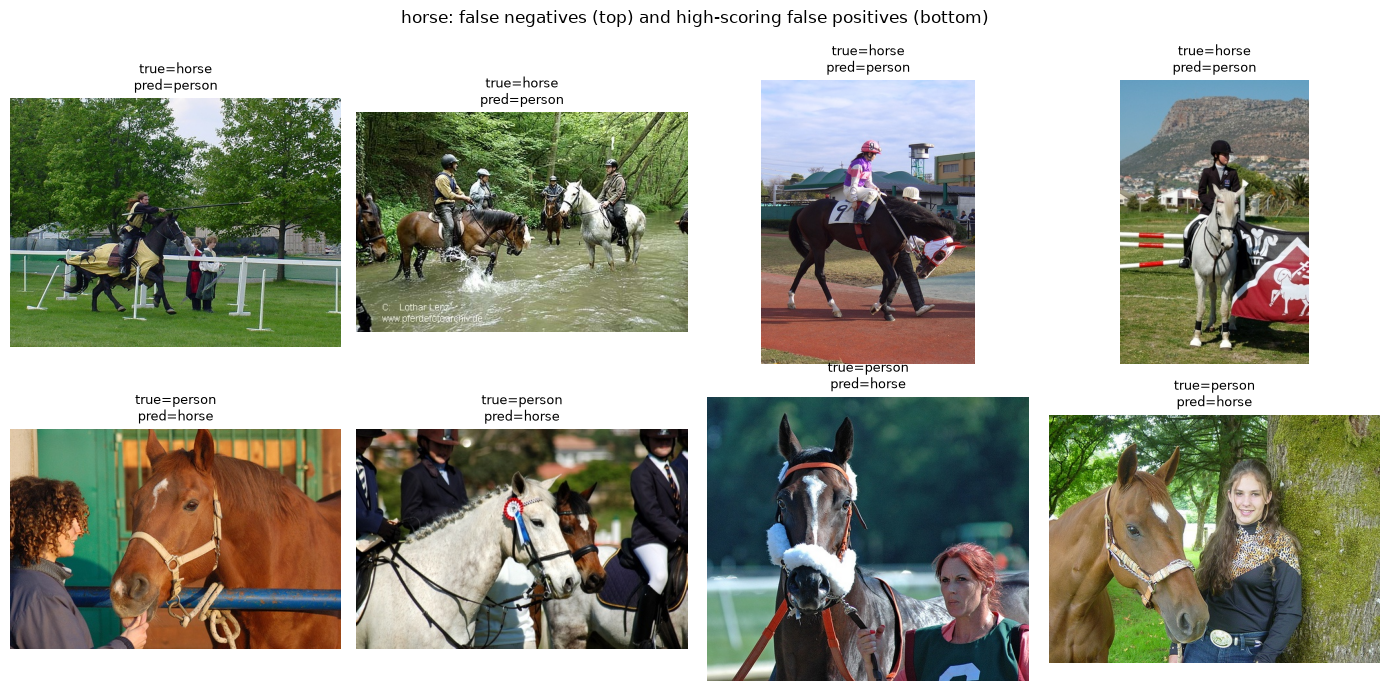

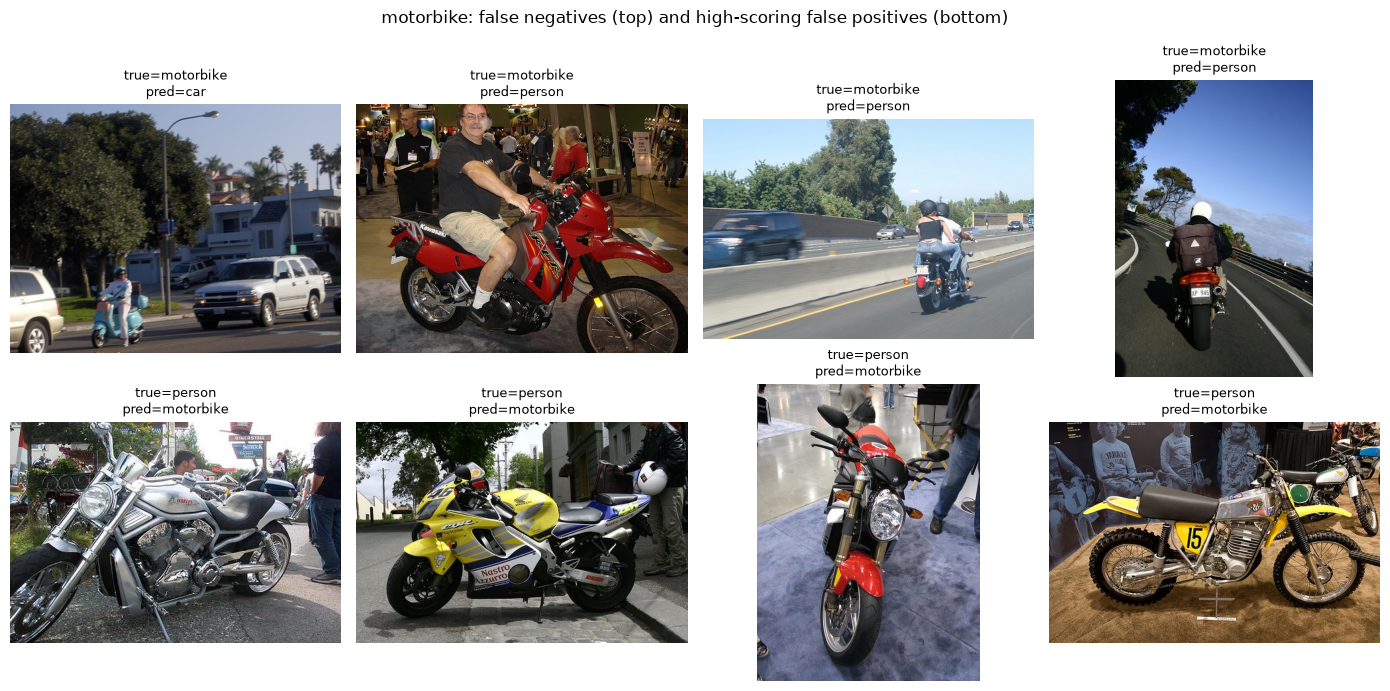

Using cached features: data/deep_features/resnet18_features.npz


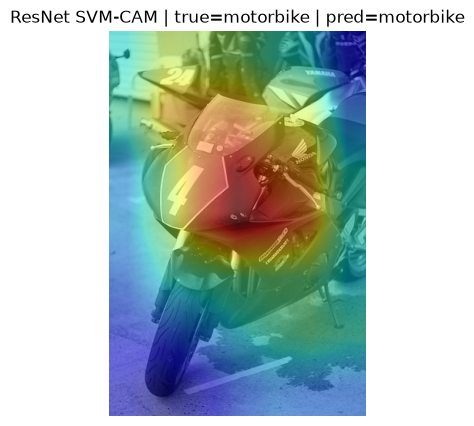

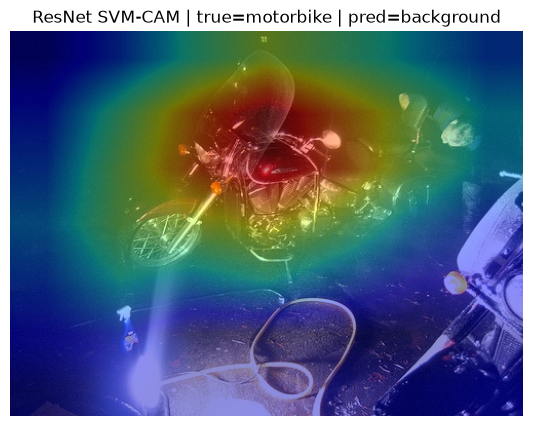

In [7]:
# Show representative DINOv2 errors for the two lowest-AP categories.
dino_data = get_or_extract_features("dinov2_vits14")
x_train_dino = normalize(dino_data["x_train"], norm="l2")
x_val_dino = normalize(dino_data["x_val"], norm="l2")
dino_svm = LinearSVC(C=1.0, max_iter=20_000, random_state=42)
dino_svm.fit(x_train_dino, dino_data["y_train"])
dino_scores = dino_svm.decision_function(x_val_dino)
dino_predictions = dino_svm.predict(x_val_dino)
dino_class_names = list(dino_svm.classes_)

for category in ("horse", "motorbike"):
    col = dino_class_names.index(category)
    true_category = val_df["category"].to_numpy()
    false_negative = np.flatnonzero(
        (true_category == category) & (dino_predictions != category)
    )[:4]
    false_positive_rank = np.flatnonzero(true_category != category)
    false_positive_rank = false_positive_rank[
        np.argsort(dino_scores[false_positive_rank, col])[::-1][:4]
    ]
    selected = list(false_negative) + list(false_positive_rank)

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for j, idx in enumerate(selected):
        row, col_ax = divmod(j, 4)
        ax = axes[row, col_ax]
        with Image.open(val_df.iloc[idx]["filepath"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(
            f"true={true_category[idx]}\npred={dino_predictions[idx]}",
            fontsize=9,
        )
        ax.axis("off")
    fig.suptitle(f"{category}: false negatives (top) and high-scoring false positives (bottom)")
    fig.tight_layout()
    plt.show()

# Task-specific ResNet CAM using the trained multiclass linear SVM weights.
import torch.nn.functional as F

resnet_data = get_or_extract_features("resnet18")
x_train_resnet = normalize(resnet_data["x_train"], norm="l2")
x_val_resnet = normalize(resnet_data["x_val"], norm="l2")
resnet_svm = LinearSVC(C=1.0, max_iter=20_000, random_state=42)
resnet_svm.fit(x_train_resnet, resnet_data["y_train"])
resnet_predictions = resnet_svm.predict(x_val_resnet)

resnet_model, resnet_preprocess = getModel("resnet18", device=device, nofc=True)
resnet_extractor = IntermediateFeatureExtractor(resnet_model)
cam_class = "motorbike"
class_row = list(resnet_svm.classes_).index(cam_class)
# The last 512 entries correspond to globally pooled layer4 channels (128+256+512 total).
channel_weights = torch.as_tensor(
    resnet_svm.coef_[class_row, -512:], device=device, dtype=torch.float32
)

correct = np.flatnonzero(
    (val_df["category"].to_numpy() == cam_class)
    & (resnet_predictions == cam_class)
)
incorrect = np.flatnonzero(
    (val_df["category"].to_numpy() == cam_class)
    & (resnet_predictions != cam_class)
)
cam_indices = [idx for idx in (correct[:1].tolist() + incorrect[:1].tolist())]

for idx in cam_indices:
    row = val_df.iloc[idx]
    with Image.open(row["filepath"]) as image:
        image = image.convert("RGB")
        batch = resnet_preprocess(image).unsqueeze(0).to(device)
        with torch.inference_mode():
            _, maps = resnet_extractor(batch)
            activation = maps["layer4.1"][0]
            cam = torch.relu((activation * channel_weights[:, None, None]).sum(dim=0))
            cam = F.interpolate(
                cam[None, None], size=(image.height, image.width),
                mode="bilinear", align_corners=False,
            )[0, 0].cpu().numpy()
        cam = cam / max(float(cam.max()), 1e-8)

        plt.figure(figsize=(7, 5))
        plt.imshow(image)
        plt.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        plt.title(
            f"ResNet SVM-CAM | true={row['category']} | "
            f"pred={resnet_predictions[idx]}"
        )
        plt.axis("off")
        plt.show()

resnet_extractor.remove_hooks()